In [280]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import importlib
import feature_utils
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.ensemble import IsolationForest
from scipy import signal

importlib.reload(feature_utils)
from feature_utils import plot_rms_violin,find_active_periods,compare_waveforms, calculate_raw_waveform_rms

DATA_PATH = Path("centrifuge line datasets.parquet")
if not DATA_PATH.exists():
    import gdown

    print("Dataset not found locally. Downloading from Google Drive...")
    temporary_path = DATA_PATH.with_suffix(".parquet.part")

    try:
        downloaded = gdown.download(
            id="1gQFwz2n2L9yNq_kB1qfsDSvt0BW68hXb",
            output=str(temporary_path),
            quiet=False,
        )

        if downloaded is None or not temporary_path.exists():
            raise RuntimeError(
                "Download failed. Check your internet connection and "
                "ensure the Google Drive file allows public downloads."
            )

        # Validate before saving under the final dataset filename.
        pq.ParquetFile(temporary_path)
        temporary_path.replace(DATA_PATH)

    except Exception:
        temporary_path.unlink(missing_ok=True)
        raise

print(f"Using dataset: {DATA_PATH.resolve()}")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
pf = pq.ParquetFile(DATA_PATH)
display(pd.DataFrame({"column": pf.schema_arrow.names,
                      "parquet_type": [str(f.type) for f in pf.schema_arrow]}))
print(f"Rows: {pf.metadata.num_rows:,}; file size: {DATA_PATH.stat().st_size / 1024**2:.1f} MiB")
df = pq.read_table(DATA_PATH).to_pandas()






Dataset not found locally. Downloading from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1gQFwz2n2L9yNq_kB1qfsDSvt0BW68hXb
From (redirected): https://drive.google.com/uc?id=1gQFwz2n2L9yNq_kB1qfsDSvt0BW68hXb&confirm=t&uuid=294abe23-473e-41c1-8b66-3f3749bf3ce3
To: /Users/vinura/Work/Personal/Interviews/Groundupai/Vinura_Wanniarachchi_AIMLEngineer_Groundup/centrifuge line datasets.parquet.part
100%|██████████| 524M/524M [03:27<00:00, 2.52MB/s] 

Using dataset: /Users/vinura/Work/Personal/Interviews/Groundupai/Vinura_Wanniarachchi_AIMLEngineer_Groundup/centrifuge line datasets.parquet


,column,parquet_type
0,date,"timestamp[ns, tz=UTC]"
1,Motor DE_Z Short Wave High Frequency,list<element: double>
2,Motor DE_Z Long Wave High Frequency,list<element: double>
3,Motor DE_X Short Wave Low Frequency,list<element: double>
4,Motor DE_Y Short Wave Low Frequency,list<element: double>
5,Motor DE_Z Short Wave Low Frequency,list<element: double>
6,Motor DE_Temperature,list<element: double>
7,Motor DE_Z Short Wave Low Frequency RMS,double
8,Motor DE_X Short Wave Low Frequency RMS,double
9,Motor DE_Y Short Wave Low Frequency RMS,double


Rows: 26,502; file size: 499.8 MiB


### Separate development and holdout data


In [281]:

df["date"] = pd.to_datetime(df["date"], utc=True)

# Timestamp-based record types are a heuristic; validate against waveform presence.


final_test_mask = (
    (df["date"] >= "2025-04-29 00:00:00+00:00") &
    (df["date"] < "2025-06-10 00:00:00+00:00")
)

# Keep all records for waveform inspection and paired RMS comparisons.
df_dev = df.loc[~final_test_mask].copy()
df_hold_out = df.loc[final_test_mask].copy()


assert len(df) == len(df_dev) + len(df_hold_out)


Timestamps are converted to UTC. Records from **29 April 2025 up to, but excluding, 10 June 2025** are reserved as holdout data; the remaining records form the development dataset. The assertion checks that the split preserves every row. Feature selection, fitting, and threshold calibration below use development data. The holdout is scored later without refitting.


### Calculate raw high-frequency waveform RMS


In [282]:
CALCULATED_SHF_RMS_COL = "Motor DE_Z Short Wave High Frequency RMS calculated"
CALCULATED_LHF_RMS_COL = "Motor DE_Z Long Wave High Frequency RMS calculated"
df_dev[CALCULATED_SHF_RMS_COL] = df_dev[
    "Motor DE_Z Short Wave High Frequency"
].map(calculate_raw_waveform_rms)

df_dev[CALCULATED_LHF_RMS_COL] = df_dev[
    "Motor DE_Z Long Wave High Frequency"
].map(calculate_raw_waveform_rms)

The existing `calculate_raw_waveform_rms` helper calculates RMS directly from the Z-axis short- and long-wave high-frequency waveforms. Missing, empty, or non-finite waveforms return `NaN`. These are raw waveform summaries, distinct from the processed acceleration and velocity RMS features extracted later. Calculated short-wave RMS is used to select running recordings.


### Construct the labelled operating-period subsets


In [283]:
# Use your specified period labels; these are not independently verified.
dates = pd.to_datetime(df_dev["date"], utc=True, errors="coerce")
rms = pd.to_numeric(df_dev[CALCULATED_SHF_RMS_COL], errors="coerce")
valid_rms = np.isfinite(rms) & (rms > 13)

periods = {
    "known_bearing_fault": (
        "2025-01-02 08:01:20+00:00",
        "2025-01-04 02:21:20+00:00",
    ),
    "healthy": (
        "2025-01-09 02:11:20+00:00",
        "2025-03-24 12:31:20+00:00",
    ),
    "suspicious": (
        "2025-03-24 16:31:20+00:00",
        "2025-04-28 23:51:20+00:00",
    ),
}

subsets = {}

for label, (start, end) in periods.items():
    mask = valid_rms & dates.between(
        pd.Timestamp(start),
        pd.Timestamp(end),
        inclusive="both",
    )
    subset = df_dev.loc[mask].copy()
    subset["date"] = dates.loc[mask]
    subsets[label] = subset.sort_values("date")

df_known_bearing_fault = subsets["known_bearing_fault"]
df_healthy = subsets["healthy"]
df_suspicious = subsets["suspicious"]

for label, subset in subsets.items():
    print(f"{label}: {len(subset):,} rows")

known_bearing_fault: 39 rows
healthy: 430 rows
suspicious: 276 rows


Development recordings are grouped into the specified **known bearing fault**, **healthy**, and **suspicious** date ranges. Only recordings with finite calculated short-wave high-frequency RMS **greater than 13** are retained, treating sufficient vibration as a proxy for running operation.

The saved output contains **39 fault-labelled**, **430 healthy**, and **276 suspicious** recordings. The period labels are supplied assumptions rather than diagnoses independently established by this analysis. The suspicious group is therefore assessed for anomalies, not treated as confirmed positive ground truth.


### Extract acceleration and velocity signal features


In [284]:
import feature_utils

WAVE_FS = {
    "Motor DE_Z Short Wave High Frequency": 51200,
    "Motor DE_Z Long Wave High Frequency": 51200,
    "Motor DE_Z Short Wave Low Frequency": 5120,
    "Motor DE_X Short Wave Low Frequency": 4001,
    "Motor DE_Y Short Wave Low Frequency": 4001,
    "Motor DE_Audio Signal": 11025,
}

def extract_signal_features(df, wave_fs):
    feature_dfs = {}

    columns = [
        "row_index",
        "date",
        "acceleration_rms",
        "acceleration_fft",
        "velocity_rms",
        "velocity_fft",
    ]

    for signal_col, sampling_rate in wave_fs.items():
        # Audio does not use acceleration/velocity processing.
        if signal_col == "Motor DE_Audio Signal":
            continue

        records = []

        for index, row in df.iterrows():
            value = row[signal_col]

            if value is None or np.isscalar(value):
                continue

            waveform = np.asarray(value, dtype=float).ravel()

            if waveform.size < 8 or not np.isfinite(waveform).all():
                continue

            features = feature_utils.get_features(waveform, sampling_rate)

            records.append({
                "row_index": index,
                "date": row["date"],
                **features,
            })

        feature_dfs[signal_col] = pd.DataFrame(
            records, columns=columns
        )

    return feature_dfs



features_fault = extract_signal_features(df_known_bearing_fault, WAVE_FS)
features_healthy = extract_signal_features(df_healthy, WAVE_FS)
features_suspicious = extract_signal_features(df_suspicious, WAVE_FS)
df_known_bearing_fault.head()

,date,Motor DE_Z Short Wave High Frequency,Motor DE_Z Long Wave High Frequency,Motor DE_X Short Wave Low Frequency,Motor DE_Y Short Wave Low Frequency,Motor DE_Z Short Wave Low Frequency,Motor DE_Temperature,Motor DE_Z Short Wave Low Frequency RMS,Motor DE_X Short Wave Low Frequency RMS,Motor DE_Y Short Wave Low Frequency RMS,Motor DE_Z Speed Total Value,Motor DE_X Speed Total Value,Motor DE_Y Speed Total Value,Motor DE_Z Short Wave High Frequency RMS,Motor DE_Audio Decibels,Motor DE_Magnetic Leakage RMS,Motor DE_Audio Signal,Motor DE_Z Short Wave High Frequency RMS calculated,Motor DE_Z Long Wave High Frequency RMS calculated
88,2025-01-02 09:00:00+00:00,"[-21.56786930368071, -11.455289212919524, 4.38...",None,"[23.177496646465443, 25.178296607853554, 25.17...","[3.3878808408699115, 4.505400819303759, 4.5054...","[-0.2729988305751867, 14.91234130571441, 11.00...",[44.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,24.499644,NaN
96,2025-01-02 10:00:00+00:00,"[-38.9958838424227, -39.835853849961495, -21.6...",None,"[0.47225627213629195, -7.735903569460788, -7.7...","[64.09811346614515, 25.897474203349702, 25.897...","[-7.287374596654747, 7.140345532835152, 10.236...",[49.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,28.560379,NaN
104,2025-01-02 11:00:00+00:00,"[-38.59483169893065, -6.840671413934615, 29.24...","[-27.960602000063545, -50.44215220183719, -39....","[-4.693675409420393, 2.4067244535544887, 2.406...","[16.380690918256732, -2.0315487264197145, -2.0...","[13.20267808724505, 7.2570080338822045, 11.868...",[52.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,31.040945,29.846073
112,2025-01-02 12:00:00+00:00,"[-11.685273102312749, -23.049573204308217, -20...",None,"[4.603951083026914, -4.082448749340983, -4.082...","[-23.886638789030258, -7.4361591064953245, -7....","[-4.666793127822327, -7.104353149699616, -7.00...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,30.146071,NaN
120,2025-01-02 13:00:00+00:00,"[11.315996880736748, -6.89982328275164, -9.205...",None,"[-5.022380574951967, -0.44494066328843473, -0....","[-20.896500815484615, 11.535978558626084, 11.5...","[23.250786419615096, -11.319743890658074, 10.9...",[53.0],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,29.645817,NaN


The notebook extends the provided utilities by applying `feature_utils.get_features` to each valid waveform using its configured sampling rate. Acceleration preprocessing converts to g, applies a 10 Hz highpass filter, detrends, trims the initial settling interval, and removes the mean. Velocity preprocessing converts acceleration to mm/s², integrates it, applies a **10–1000 Hz bandpass**, detrends, trims, and removes the mean. These conversions assume the raw acceleration units are m/s².

For each signal, the utility returns processed acceleration RMS, velocity RMS, and Welch spectra represented as RMS amplitude per frequency bin. Original row identifiers and timestamps are retained to align channels. Audio is excluded because acceleration-to-velocity processing is inappropriate for that signal. Invalid waveforms are skipped per channel rather than requiring every channel to be present.


### Engineer the selected frequency-band features


In [285]:


def selected_band_features(
    spectrum, low, high, analysis_low, analysis_high
):
    if not isinstance(spectrum, (tuple, list)) or len(spectrum) != 2:
        return np.nan, np.nan

    f = np.asarray(spectrum[0], dtype=float)
    a = np.asarray(spectrum[1], dtype=float)

    if (
        f.ndim != 1
        or a.shape != f.shape
        or f.size < 2
        or not np.isfinite(f).all()
        or not np.isfinite(a).all()
        or not np.all(np.diff(f) > 0)
        or f[0] > analysis_low
        or f[-1] < analysis_high
    ):
        return np.nan, np.nan

    power = a ** 2
    band = (f >= low) & (f < high)
    analysis = (f >= analysis_low) & (f < analysis_high)

    if not band.any():
        return np.nan, np.nan

    band_power = power[band].sum()
    total_power = power[analysis].sum()

    return (
        float(np.sqrt(band_power)),
        float(band_power / total_power) if total_power > 0 else np.nan,
    )


def build_selected_features(feature_dfs):
    selections = [
        (
                    "Motor DE_X Short Wave Low Frequency",
                    "acceleration_fft",
                    100, 500, 10, 1500,
                    "x_acc_100_500", True,
                ),
                (
                    "Motor DE_Z Short Wave High Frequency",
                    "acceleration_fft",
                    2500, 5000, 10, 10000,
                    "z_acc_2500_5000", True,
                ),
                (
                    "Motor DE_Y Short Wave Low Frequency",
                    "acceleration_fft",
                    100, 500, 10, 1500,
                    "y_acc_100_500", False,
                ),
        (
            "Motor DE_X Short Wave Low Frequency",
            "velocity_fft",
            100, 500, 10, 1500,
            "x_vel_100_500", True,
        ),
        (
            "Motor DE_Y Short Wave Low Frequency",
            "velocity_fft",
            100, 500, 10, 1500,
            "y_vel_100_500", True,
        ),
    ]

    # Preserve every recording available in the feature dictionaries.
    metadata = []
    for signal, source in feature_dfs.items():
        if source["row_index"].duplicated().any():
            raise ValueError(f"Duplicate row indexes in {signal}.")
        metadata.append(source[["row_index", "date"]])

    if not metadata:
        return pd.DataFrame(columns=["row_index", "date"])

    metadata = pd.concat(metadata, ignore_index=True)

    date_counts = metadata.groupby("row_index")["date"].nunique()
    if (date_counts > 1).any():
        raise ValueError("The same row_index has conflicting dates.")

    combined = (
        metadata.groupby("row_index", sort=False, as_index=False)
        .agg(date=("date", "first"))
    )

    # Selected frequency-band features.
    for signal, fft_col, low, high, start, end, prefix, include_rms in selections:
        source = feature_dfs[signal]
        table = source[["row_index"]].copy()

        pairs = [
            selected_band_features(s, low, high, start, end)
            for s in source[fft_col]
        ]

        if include_rms:
            table[f"{prefix}_rms"] = [rms for rms, fraction in pairs]

        table[f"{prefix}_power_fraction"] = [
            fraction for rms, fraction in pairs
        ]

        combined = combined.merge(
            table,
            on="row_index",
            how="left",
            validate="one_to_one",
        )

    # Overall RMS values already extracted by feature_utils.get_features().
    for signal, source in feature_dfs.items():
        overall_rms = source[
            ["row_index", "acceleration_rms", "velocity_rms"]
        ].rename(columns={
            "acceleration_rms": f"{signal} | acceleration_rms",
            "velocity_rms": f"{signal} | velocity_rms",
        })

        combined = combined.merge(
            overall_rms,
            on="row_index",
            how="left",
            validate="one_to_one",
        )

    return combined.sort_values("date").reset_index(drop=True)

The selected bands from Q1 are converted into numeric features. **Band RMS** is the square root of summed squared spectral-bin amplitudes within the selected band. **Power fraction** divides that band power by power within a fixed reference range.

| Prefix | Channel and spectrum | Selected band | Reference range | Features retained |
|---|---|---|---|---|
| `x_acc_100_500` | X low-frequency acceleration | 100–500 Hz | 10–1500 Hz | RMS and power fraction |
| `z_acc_2500_5000` | Z short-wave high-frequency acceleration | 2500–5000 Hz | 10–10000 Hz | RMS and power fraction |
| `y_acc_100_500` | Y low-frequency acceleration | 100–500 Hz | 10–1500 Hz | Power fraction only |
| `x_vel_100_500` | X low-frequency velocity | 100–500 Hz | 10–1500 Hz | RMS and power fraction |
| `y_vel_100_500` | Y low-frequency velocity | 100–500 Hz | 10–1500 Hz | RMS and power fraction |

These bands were chosen for observed differences between healthy and fault-labelled development recordings. They are empirical candidates, not confirmed bearing characteristic frequencies. The tuple's final boolean controls inclusion of band RMS; power fraction is always included. Overall acceleration and velocity RMS values are also retained as candidate features. Joins preserve available recordings and check row/date consistency.

Velocity power fractions describe the **processed** spectrum: the 10–1000 Hz velocity filter attenuates the upper part of the 10–1500 Hz reference range. The Z acceleration denominator is 10–10000 Hz, which differs from the broader denominator in the Q1 short-wave comparison chart.


### Build aligned feature tables for the three groups


In [286]:
df_fault_selected = build_selected_features(features_fault)
df_healthy_selected = build_selected_features(features_healthy)
df_suspicious_selected = build_selected_features(features_suspicious)

display(df_fault_selected.head())

,row_index,date,x_acc_100_500_rms,x_acc_100_500_power_fraction,z_acc_2500_5000_rms,z_acc_2500_5000_power_fraction,y_acc_100_500_power_fraction,x_vel_100_500_rms,x_vel_100_500_power_fraction,y_vel_100_500_rms,...,Motor DE_Z Short Wave High Frequency | acceleration_rms,Motor DE_Z Short Wave High Frequency | velocity_rms,Motor DE_Z Long Wave High Frequency | acceleration_rms,Motor DE_Z Long Wave High Frequency | velocity_rms,Motor DE_Z Short Wave Low Frequency | acceleration_rms,Motor DE_Z Short Wave Low Frequency | velocity_rms,Motor DE_X Short Wave Low Frequency | acceleration_rms,Motor DE_X Short Wave Low Frequency | velocity_rms,Motor DE_Y Short Wave Low Frequency | acceleration_rms,Motor DE_Y Short Wave Low Frequency | velocity_rms
0,88,2025-01-02 09:00:00+00:00,0.529336,0.803326,1.832005,0.544975,0.694322,4.620906,0.868966,3.341644,...,2.504863,5.532466,NaN,NaN,0.990084,5.529258,0.622187,4.996879,0.593271,3.737488
1,96,2025-01-02 10:00:00+00:00,0.584327,0.856423,2.055086,0.545665,0.711342,5.255919,0.920839,2.907723,...,2.901774,3.997837,NaN,NaN,0.938407,4.119979,0.661592,5.486672,0.556680,3.267842
2,104,2025-01-02 11:00:00+00:00,0.633134,0.866214,2.457342,0.605572,0.739211,5.774103,0.917960,3.190431,...,3.169505,4.079892,3.037287,4.10641,0.944248,4.108563,0.707120,6.022675,0.581952,3.481987
3,112,2025-01-02 12:00:00+00:00,0.635856,0.848950,2.219234,0.528733,0.750566,5.792684,0.896656,3.299978,...,3.072572,3.862678,NaN,NaN,0.972037,3.936128,0.710431,6.073979,0.589258,3.521877
4,120,2025-01-02 13:00:00+00:00,0.642986,0.863319,2.240043,0.575819,0.735221,5.894908,0.904531,3.261029,...,3.022631,3.824368,NaN,NaN,0.968778,3.862781,0.715730,6.191397,0.589265,3.489178


The same feature-building function is applied to the fault-labelled, healthy, and suspicious recordings. Each table contains one row per original recording, its timestamp, and the engineered numeric features. The displayed fault rows provide a check of feature names and values. Missing channels remain missing after alignment and are handled when preparing each model's inputs.


### Create complete-case candidate feature matrices


In [287]:
feature_columns = [
    col for col in df_fault_selected.columns
    if col not in ["row_index", "date"]
]

X_fault = df_fault_selected.dropna(subset=feature_columns)[feature_columns]
X_healthy = df_healthy_selected.dropna(subset=feature_columns)[feature_columns]
X_suspicious = df_suspicious_selected.dropna(subset=feature_columns)[feature_columns]

This block creates numeric matrices after excluding identifiers and dropping rows missing **any** candidate feature. Because overall long-wave RMS features are included, this exploratory filter can discard otherwise usable short-wave recordings. These matrices are not used by the subsequent training workflow, which instead requires completeness only for its chosen model features.


### Define a healthy-reference Isolation Forest and training procedure


In [288]:

FEATURE_COLUMNS = [
    "x_acc_100_500_rms",
    "x_acc_100_500_power_fraction",
    "z_acc_2500_5000_rms",
    "z_acc_2500_5000_power_fraction",
    "y_acc_100_500_power_fraction",
    "x_vel_100_500_power_fraction",
    "y_vel_100_500_power_fraction",
    "z_hf_envelope_median_5_500",
]


def add_run_ids(feature_df, active_periods):
    """Match recordings to the observed active-period boundaries."""
    data = feature_df.copy()
    data["date"] = pd.to_datetime(data["date"], utc=True)
    data["run_id"] = pd.Series(pd.NA, index=data.index, dtype="Int64")

    for run_id, period in active_periods.iterrows():
        mask = data["date"].between(
            period["first_active"], period["last_active"],
            inclusive="both",
        )

        if data.loc[mask, "run_id"].notna().any():
            raise ValueError("Active periods overlap.")

        data.loc[mask, "run_id"] = int(run_id)

    return data


def train_anomaly_baseline(
    reference_df,
    other_groups,
    feature_columns=FEATURE_COLUMNS,
    validation_fraction=0.25,
    target_false_alarm_rate=0.05,
):
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be between 0 and 1.")
    if not 0 < target_false_alarm_rate < 1:
        raise ValueError("target_false_alarm_rate must be between 0 and 1.")

    def clean(df, label):
        data = df.copy()
        data["date"] = pd.to_datetime(data["date"], utc=True, errors="coerce")
        data[feature_columns] = (
            data[feature_columns]
            .apply(pd.to_numeric, errors="coerce")
            .replace([np.inf, -np.inf], np.nan)
        )
        valid = (
            data["date"].notna()
            & data[feature_columns].notna().all(axis=1)
        )
        print(f"{label}: retained {valid.sum():,}/{len(data):,} rows")
        return data.loc[valid].sort_values("date").copy()

    reference = clean(reference_df, "Reference")
    if "run_id" not in reference.columns:
        raise ValueError("Add run_id to the reference DataFrame first.")

    missing_runs = reference["run_id"].isna().sum()
    print(f"Reference recordings without a matched run: {missing_runs}")
    reference = reference.dropna(subset=["run_id"])

    run_order = (
        reference.groupby("run_id")["date"]
        .min().sort_values().index.tolist()
    )
    if len(run_order) < 2:
        raise ValueError("Need at least two reference runs.")

    n_validation = min(
        len(run_order) - 1,
        max(1, int(np.ceil(len(run_order) * validation_fraction))),
    )
    training_runs = run_order[:-n_validation]
    validation_runs = run_order[-n_validation:]

    train = reference.loc[reference["run_id"].isin(training_runs)].copy()
    validation = reference.loc[
        reference["run_id"].isin(validation_runs)
    ].copy()

    print("Training run IDs:", training_runs)
    print("Validation run IDs:", validation_runs)

    # Tree-based Isolation Forest does not require feature scaling.
    model = IsolationForest(
        n_estimators=300,
        max_samples="auto",
        contamination="auto",
        random_state=42,
        n_jobs=-1,
    )
    model.fit(train[feature_columns])

    def score(data):
        result = data.copy()
        # Higher score = more anomalous.
        result["anomaly_score"] = -model.score_samples(
            result[feature_columns]
        )
        return result

    validation = score(validation)
    threshold = float(
        validation["anomaly_score"].quantile(
            1 - target_false_alarm_rate
        )
    )

    scored = {
        "Reference training": score(train),
        "Reference validation": validation,
    }

    for label, df in other_groups.items():
        data = clean(df, label)
        scored[label] = (
            score(data) if not data.empty
            else data.assign(anomaly_score=pd.Series(dtype=float))
        )

    summary = []
    for label, data in scored.items():
        data["anomaly"] = data["anomaly_score"] > threshold
        summary.append({
            "group": label,
            "recordings": len(data),
            "flagged": int(data["anomaly"].sum()),
            "flagged_pct": (
                100 * data["anomaly"].mean() if len(data) else np.nan
            ),
            "median_score": data["anomaly_score"].median(),
        })

    print(f"\nFrozen score threshold: {threshold:.4f}")
    display(pd.DataFrame(summary).set_index("group").round(3))

    fig, axes = plt.subplots(
        len(scored), 1,
        figsize=(15, 3 * len(scored)),
        sharey=True,
        squeeze=False,
    )

    for ax, (label, data) in zip(axes[:, 0], scored.items()):
        ax.scatter(
            data["date"], data["anomaly_score"],
            c=np.where(data["anomaly"], "red", "tab:blue"),
            s=15, alpha=0.6,
        )
        ax.axhline(threshold, color="black", linestyle="--")
        ax.set_title(label)
        ax.set_ylabel("Anomaly score")
        ax.set_xlabel("Date (UTC)")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return model, threshold, scored

An **Isolation Forest** is used because the healthy period provides a reference distribution, while confirmed fault examples are limited to one short period and the suspicious labels are uncertain. The model learns departures from healthy operation without fitting a supervised fault classifier. It is suitable as an anomaly baseline, but its score does not identify a fault mechanism or represent a calibrated fault probability.

Training uses **300 trees**, `max_samples="auto"`, `contamination="auto"`, and a fixed random seed of **42**. Features are supplied without scaling. Missing or non-finite selected features are excluded. Healthy runs are ordered chronologically, with the latest approximately **25% of runs** assigned to validation. Keeping whole runs together reduces leakage between neighboring recordings from the same run.

The model is fitted only on healthy training recordings. Anomaly scores are defined as the negative of `score_samples`, so larger values indicate greater abnormality. The **95th percentile of healthy validation scores** defines the threshold for a nominal 5% false-alarm target; scores above it are flagged. The manually calibrated threshold is used instead of the estimator's built-in prediction threshold.

**Evaluation limitation:** these healthy validation recordings calibrate the threshold and are also used in the reported metrics. Their false-alarm rate is a calibration result, not an independent estimate of future performance. Feature choices also use development-group observations, so reported development metrics are exploratory.


### Engineer a high-frequency envelope-spectrum feature


In [289]:
def envelope_spectrum_median(
    waveform,
    sampling_rate=51200,
    carrier_band=(1800, 4500),
    envelope_band=(5, 500),
):
    if waveform is None or np.isscalar(waveform):
        return np.nan

    x = np.asarray(waveform, dtype=float).ravel()

    if x.size < 64 or not np.isfinite(x).all():
        return np.nan

    low, high = carrier_band
    env_low, env_high = envelope_band

    if not 0 < low < high < sampling_rate / 2:
        raise ValueError("Carrier band must be below Nyquist.")

    if not 0 < env_low < env_high < sampling_rate / 2:
        raise ValueError("Envelope band must be below Nyquist.")

    # Use the same acceleration preprocessing as your other features.
    x = feature_utils.preprocess_acceleration(x, sampling_rate)

    sos = signal.butter(
        4,
        carrier_band,
        btype="bandpass",
        fs=sampling_rate,
        output="sos",
    )
    filtered = signal.sosfiltfilt(sos, x)

    # Hilbert envelope, with boundary trimming.
    envelope = np.abs(signal.hilbert(filtered))
    trim = max(1, int(envelope.size * 0.05))
    envelope = envelope[trim:-trim]
    envelope -= envelope.mean()

    # Full-record Hann spectrum: RMS amplitude per bin.
    frequencies, psd = signal.welch(
        envelope,
        fs=sampling_rate,
        window="hann",
        nperseg=envelope.size,
        noverlap=0,
        detrend=False,
        scaling="density",
    )

    frequency_step = frequencies[1] - frequencies[0]
    rms_per_bin = np.sqrt(psd * frequency_step)

    mask = (
        (frequencies >= env_low)
        & (frequencies <= env_high)
    )

    return float(np.median(rms_per_bin[mask])) if mask.any() else np.nan

A new utility derives an envelope feature from the Z short-wave high-frequency waveform. After acceleration preprocessing, a zero-phase **1800–4500 Hz bandpass** selects the carrier signal. The magnitude of its Hilbert transform gives the envelope. The code trims 5% from each boundary, removes the envelope mean, and calculates a full-record Hann/Welch spectrum.

The feature is the **median RMS spectral-bin amplitude between 5 and 500 Hz**. It summarizes modulation in the filtered high-frequency signal and provides a candidate descriptor beyond the ordinary acceleration and velocity bands. It is not integrated envelope-band RMS, and does not identify specific bearing defect frequencies. Carrier and envelope ranges are analysis choices whose robustness should be checked on additional data.


### Attach envelope features to the recording tables


In [290]:
ENVELOPE_FEATURE = "z_hf_envelope_median_5_500"
HF_WAVE_COLUMN = "Motor DE_Z Short Wave High Frequency"


def add_envelope_feature(feature_df, raw_df):
    features = feature_df.copy()

    required = ["date", HF_WAVE_COLUMN]
    missing = [column for column in required if column not in raw_df.columns]

    if missing:
        raise KeyError(f"Missing raw-data columns: {missing}")

    if not {"row_index", "date"}.issubset(features.columns):
        raise KeyError("Feature table needs row_index and date columns.")

    envelope_data = raw_df[required].copy()
    envelope_data.insert(
        0, "row_index", raw_df.index.to_numpy()
    )

    envelope_data["date"] = pd.to_datetime(
        envelope_data["date"], utc=True, errors="coerce"
    )
    features["date"] = pd.to_datetime(
        features["date"], utc=True, errors="coerce"
    )

    envelope_data[ENVELOPE_FEATURE] = envelope_data[
        HF_WAVE_COLUMN
    ].apply(
        lambda waveform: envelope_spectrum_median(
            waveform,
            sampling_rate=51200,
            carrier_band=(1800, 4500),
            envelope_band=(5, 500),
        )
    )

    # Replace an existing version of this feature when rerunning.
    features = features.drop(
        columns=[ENVELOPE_FEATURE], errors="ignore"
    )

    result = features.merge(
        envelope_data[["row_index", "date", ENVELOPE_FEATURE]],
        on=["row_index", "date"],
        how="left",
        validate="one_to_one",
    )

    print(
        f"Envelope feature available: "
        f"{result[ENVELOPE_FEATURE].notna().sum():,}/{len(result):,}"
    )

    return result


df_fault_extended = add_envelope_feature(
    df_fault_selected,
    df_known_bearing_fault,
)

df_healthy_extended = add_envelope_feature(
    df_healthy_selected,
    df_healthy,
)

df_suspicious_extended = add_envelope_feature(
    df_suspicious_selected,
    df_suspicious,
)

Envelope feature available: 39/39
Envelope feature available: 430/430
Envelope feature available: 276/276


The envelope feature is calculated for each group's original Z high-frequency waveforms and merged into its selected-feature table using both row identifier and timestamp. A one-to-one merge protects against duplicate matches, and an existing envelope column is replaced when rerunning. Availability counts reveal how many recordings can support envelope-based models. The resulting extended tables are the inputs to training and feature-set comparison.


### Identify operating runs for chronological validation


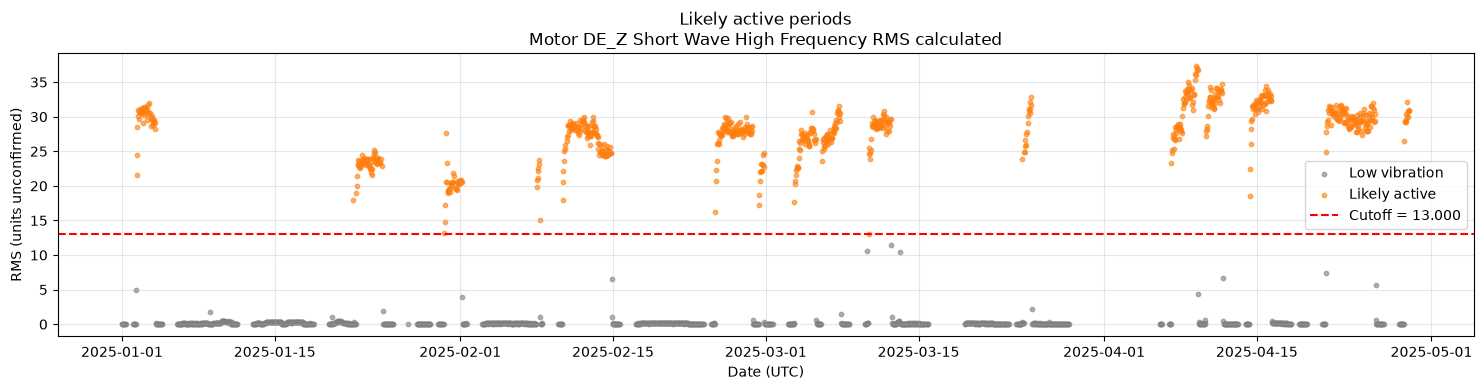

/Users/vinura/Work/Personal/Interviews/Groundupai/Vinura_Wanniarachchi_AIMLEngineer_Groundup/feature_utils.py:276: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(periods.round(3))


,first_active,last_active,readings,median_rms,observed_span_hours
run_id,,,,,
1,2025-01-02 08:00:00+00:00,2025-01-04 01:00:00+00:00,40,30.360,41.0
2,2025-01-22 05:00:00+00:00,2025-01-22 05:00:00+00:00,1,18.019,0.0
3,2025-01-22 11:00:00+00:00,2025-01-24 19:00:00+00:00,52,23.399,56.0
4,2025-01-30 13:00:00+00:00,2025-02-01 03:00:00+00:00,35,20.325,38.0
5,2025-02-08 00:00:00+00:00,2025-02-08 07:00:00+00:00,8,21.667,7.0
6,2025-02-10 09:00:00+00:00,2025-02-14 20:00:00+00:00,102,27.636,107.0
7,2025-02-24 09:00:00+00:00,2025-02-27 18:00:00+00:00,82,27.921,81.0
8,2025-02-28 09:00:00+00:00,2025-02-28 20:00:00+00:00,12,22.433,11.0
9,2025-03-03 15:00:00+00:00,2025-03-05 14:00:00+00:00,45,26.689,47.0


In [291]:
active_readings_dev, active_periods_dev = find_active_periods(
    df_dev,
    cutoff=13,
    rms_col=CALCULATED_SHF_RMS_COL,
    max_gap="4h",
)

The active-period utility groups development readings using calculated short-wave high-frequency RMS **at least 3** and a maximum gap of **4 hours**. The observed first and last active timestamps define run boundaries for assigning `run_id`.

This threshold serves run grouping and differs from the **RMS > 13** filter used to select training candidates. The four-hour gap accommodates less frequent waveform readings, but these inferred boundaries remain a vibration-based approximation of operating runs. Their accuracy affects the independence of the training/validation split.


### Fit and inspect the initial eight-feature anomaly baseline


Reference: retained 429/430 rows
Reference recordings without a matched run: 0
Training run IDs: [2, 3, 4, 5, 6, 7, 8, 9]
Validation run IDs: [10, 11, 12]
Fault-labelled: retained 39/39 rows
Suspicious: retained 271/276 rows

Frozen score threshold: 0.5738


,recordings,flagged,flagged_pct,median_score
group,,,,
Reference training,336,9,2.679,0.449
Reference validation,93,5,5.376,0.515
Fault-labelled,39,39,100.000,0.726
Suspicious,271,270,99.631,0.679


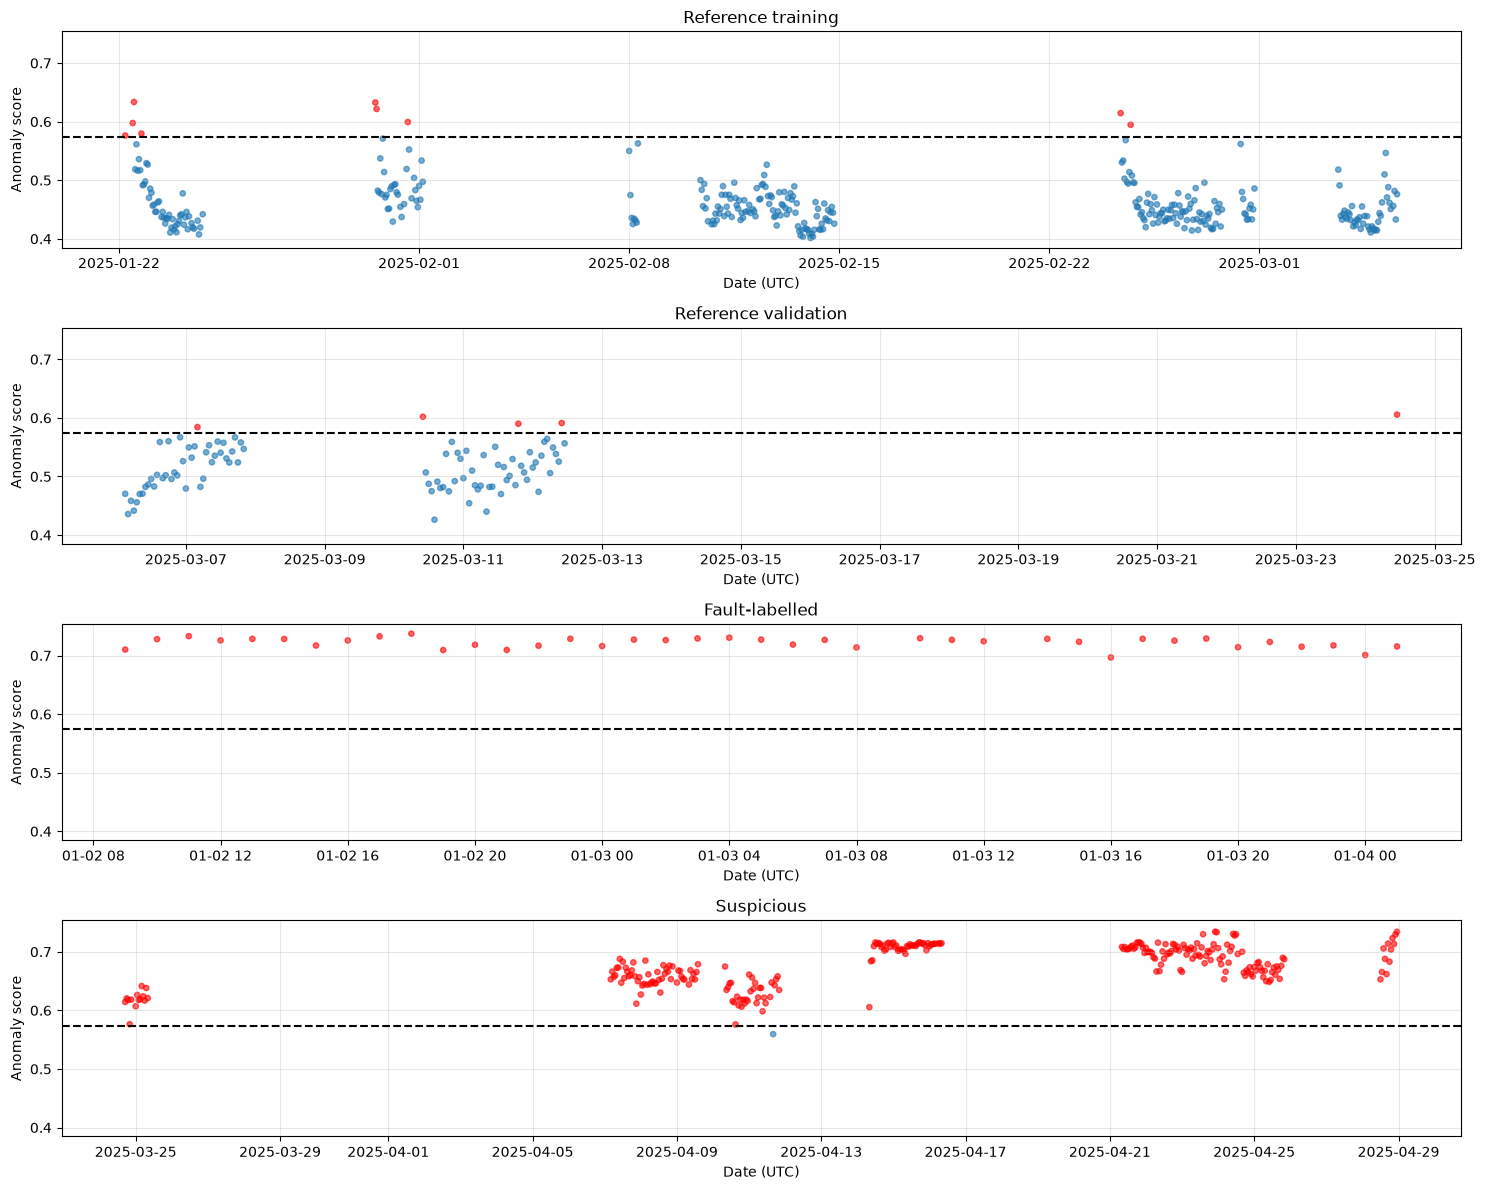

In [292]:
reference_with_runs = add_run_ids(
    df_healthy_extended,
    active_periods_dev,
)

model, anomaly_threshold, scored_groups = (
    train_anomaly_baseline(
        reference_df=reference_with_runs,
        other_groups={
            "Fault-labelled": df_fault_extended,
            "Suspicious": df_suspicious_extended,
        },
        feature_columns=FEATURE_COLUMNS,
        validation_fraction=0.25,
        target_false_alarm_rate=0.05,
    )
)

Healthy recordings are assigned run IDs and the initial eight-feature model is trained. The saved run retains **429/430 healthy**, **39/39 fault-labelled**, and **271/276 suspicious** recordings. There are **336 healthy training** and **93 healthy validation** recordings, with a frozen threshold of approximately **0.5738**.

The model flags **5/93 healthy validation recordings (5.38%)**, **39/39 fault-labelled recordings (100%)**, and **270/271 suspicious recordings (99.63%)**. This shows separation from the chosen healthy reference on the development data. Suspicious flags indicate abnormality rather than confirmed bearing faults. These counts differ slightly from the later controlled comparison, which imposes identical complete-case rows across all feature sets.


### Compare candidate features using standardized mean differences


In [293]:


def effect_size(reference, comparison):
    """
    Signed standardized mean difference using equal-weight group variances.
    Positive = comparison has a higher mean than healthy training.
    """
    a = pd.to_numeric(reference, errors="coerce").to_numpy(
        dtype=float, na_value=np.nan
    )
    b = pd.to_numeric(comparison, errors="coerce").to_numpy(
        dtype=float, na_value=np.nan
    )

    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]

    if len(a) < 2 or len(b) < 2:
        return np.nan

    denominator = np.sqrt(
        (a.var(ddof=1) + b.var(ddof=1)) / 2
    )

    if denominator == 0:
        return np.nan

    return float((b.mean() - a.mean()) / denominator)


# Use the model's actual training feature names.
trained_features = list(model.feature_names_in_)

healthy_train = scored_groups["Reference training"]
fault = scored_groups["Fault-labelled"]
suspicious = scored_groups["Suspicious"]

# Compare all available numeric features, including candidates if present.
metadata_columns = {
    "row_index",
    "date",
    "run_id",
    "anomaly_score",
    "anomaly",
}

comparison_features = [
    column
    for column in healthy_train.select_dtypes(include="number").columns
    if (
        column not in metadata_columns
        and column in fault.columns
        and column in suspicious.columns
    )
]

missing = set(trained_features) - set(comparison_features)
if missing:
    raise ValueError(f"Trained features unavailable: {sorted(missing)}")

records = []

for column in comparison_features:
    d_fault = effect_size(healthy_train[column], fault[column])
    d_suspicious = effect_size(
        healthy_train[column], suspicious[column]
    )

    records.append({
        "feature": column,
        "d_fault": d_fault,
        "d_suspicious": d_suspicious,
        "in_model": column in trained_features,
    })

separation = pd.DataFrame(records).set_index("feature")

# Compare signs before rounding; undefined effects remain unknown.
valid = separation[["d_fault", "d_suspicious"]].notna().all(axis=1)

separation["same_sign"] = pd.Series(
    pd.NA, index=separation.index, dtype="boolean"
)

separation.loc[valid, "same_sign"] = (
    np.sign(separation.loc[valid, "d_fault"])
    == np.sign(separation.loc[valid, "d_suspicious"])
)

separation["weaker_effect_magnitude"] = separation[
    ["d_fault", "d_suspicious"]
].abs().min(axis=1, skipna=False)

separation = separation.sort_values(
    "d_fault",
    key=lambda values: values.abs(),
    ascending=False,
)

print(separation.round(2).to_string())

                                                         d_fault  d_suspicious  in_model  same_sign  weaker_effect_magnitude
feature                                                                                                                     
Motor DE_X Short Wave Low Frequency | velocity_rms          9.71          1.12     False       True                     1.12
x_vel_100_500_rms                                           9.41          1.51     False       True                     1.51
y_vel_100_500_power_fraction                                7.72          2.32      True       True                     2.32
Motor DE_Z Short Wave Low Frequency | acceleration_rms      6.12          2.72     False       True                     2.72
z_acc_2500_5000_rms                                         5.01          4.08      True       True                     4.08
y_vel_100_500_rms                                           4.96          2.27     False       True                     2.27


Each available numeric feature is compared between healthy training recordings and the fault-labelled and suspicious groups. The signed effect is `(comparison mean − healthy mean) / sqrt((healthy variance + comparison variance) / 2)`. Positive values indicate higher comparison-group means. This uses equal-weight group variances and is a descriptive standardized effect, not a significance test or model feature-importance measure.

The code reports whether fault and suspicious effects have the same direction and the smaller absolute effect across the two comparisons. In the saved results, Z 2500–5000 Hz RMS (**5.01 fault; 4.08 suspicious**), the envelope feature (**3.60; 3.30**), and Y velocity power fraction (**7.72; 2.32**) show substantial changes in both groups. X acceleration power fraction separates the fault group but has almost no corresponding suspicious-group change (**2.97; −0.06**).

These observations motivate a smaller feature set. Temporal dependence between recordings and the single known-fault episode limit how broadly the effects can be generalized.


### Define baseline and reduced feature sets


In [294]:
# 1. Define the three feature sets.

BASELINE_8 = [
    "x_acc_100_500_rms",
    "x_acc_100_500_power_fraction",
    "z_acc_2500_5000_rms",
    "z_acc_2500_5000_power_fraction",
    "y_acc_100_500_power_fraction",
    "x_vel_100_500_power_fraction",
    "y_vel_100_500_power_fraction",
    "z_hf_envelope_median_5_500",
]

SMALL_4 = [
    "z_acc_2500_5000_rms",
    "z_acc_2500_5000_power_fraction",
    "z_hf_envelope_median_5_500",
    "y_vel_100_500_power_fraction",
]

SMALL_5 = SMALL_4 + [
    "Motor DE_Z Short Wave Low Frequency | acceleration_rms",
]

FEATURE_SETS = {
    "Baseline: 8 features": BASELINE_8,
    "Reduced: 4 features": SMALL_4,
    "Reduced + Z LF RMS: 5 features": SMALL_5,
}

Three feature sets are compared: the original **eight features**, a reduced **four features**, and the reduced set plus **Z low-frequency overall acceleration RMS** for a five-feature model.

The four-feature set retains Z 2500–5000 Hz acceleration RMS and power fraction, Z envelope-spectrum median, and Y 100–500 Hz velocity power fraction. These capture absolute amplitude, relative spectral distribution, and envelope behavior, with changes in both fault-labelled and suspicious groups. Reducing features simplifies extraction and interpretation, although Z RMS and its power fraction may still be correlated. The five-feature model tests whether an additional overall RMS descriptor improves results.


### Use identical recordings for a fair model comparison


In [295]:
# 2. Prepare identical evaluation rows for every model.

ALL_COMPARISON_FEATURES = list(dict.fromkeys(
    column
    for columns in FEATURE_SETS.values()
    for column in columns
))


def prepare_comparison_rows(data, label):
    missing = [
        column for column in ALL_COMPARISON_FEATURES
        if column not in data.columns
    ]
    if missing:
        raise KeyError(f"{label}: missing columns {missing}")

    result = data.copy()
    result["date"] = pd.to_datetime(
        result["date"], utc=True, errors="coerce"
    )

    result[ALL_COMPARISON_FEATURES] = (
        result[ALL_COMPARISON_FEATURES]
        .apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )

    valid = (
        result["date"].notna()
        & result[ALL_COMPARISON_FEATURES].notna().all(axis=1)
    )

    print(f"{label}: retained {valid.sum():,}/{len(result):,} rows")
    return result.loc[valid].sort_values("date").copy()


comparison_reference = prepare_comparison_rows(
    df_healthy_extended, "Healthy reference"
)
comparison_reference = add_run_ids(
    comparison_reference,
    active_periods_dev,
)

comparison_fault = prepare_comparison_rows(
    df_fault_extended, "Fault-labelled"
)
comparison_suspicious = prepare_comparison_rows(
    df_suspicious_extended, "Suspicious"
)

Healthy reference: retained 428/430 rows
Fault-labelled: retained 39/39 rows
Suspicious: retained 271/276 rows


All three models are restricted to recordings complete across the **union of their required features**. This prevents missing-data differences from changing the evaluated samples between models. The saved output retains **428/430 healthy**, **39/39 fault-labelled**, and **271/276 suspicious** recordings. Healthy recordings are then assigned to the same operating runs. This controls sample composition for the comparison, while sacrificing some recordings that a smaller model could otherwise score.


### Evaluate the three feature sets and interpret the metrics



Baseline: 8 features
Reference: retained 428/428 rows
Reference recordings without a matched run: 0
Training run IDs: [2, 3, 4, 5, 6, 7, 8, 9]
Validation run IDs: [10, 11, 12]
Fault-labelled: retained 39/39 rows
Suspicious: retained 271/271 rows

Frozen score threshold: 0.5799


,recordings,flagged,flagged_pct,median_score
group,,,,
Reference training,335,8,2.388,0.448
Reference validation,93,5,5.376,0.517
Fault-labelled,39,39,100.000,0.723
Suspicious,271,269,99.262,0.679


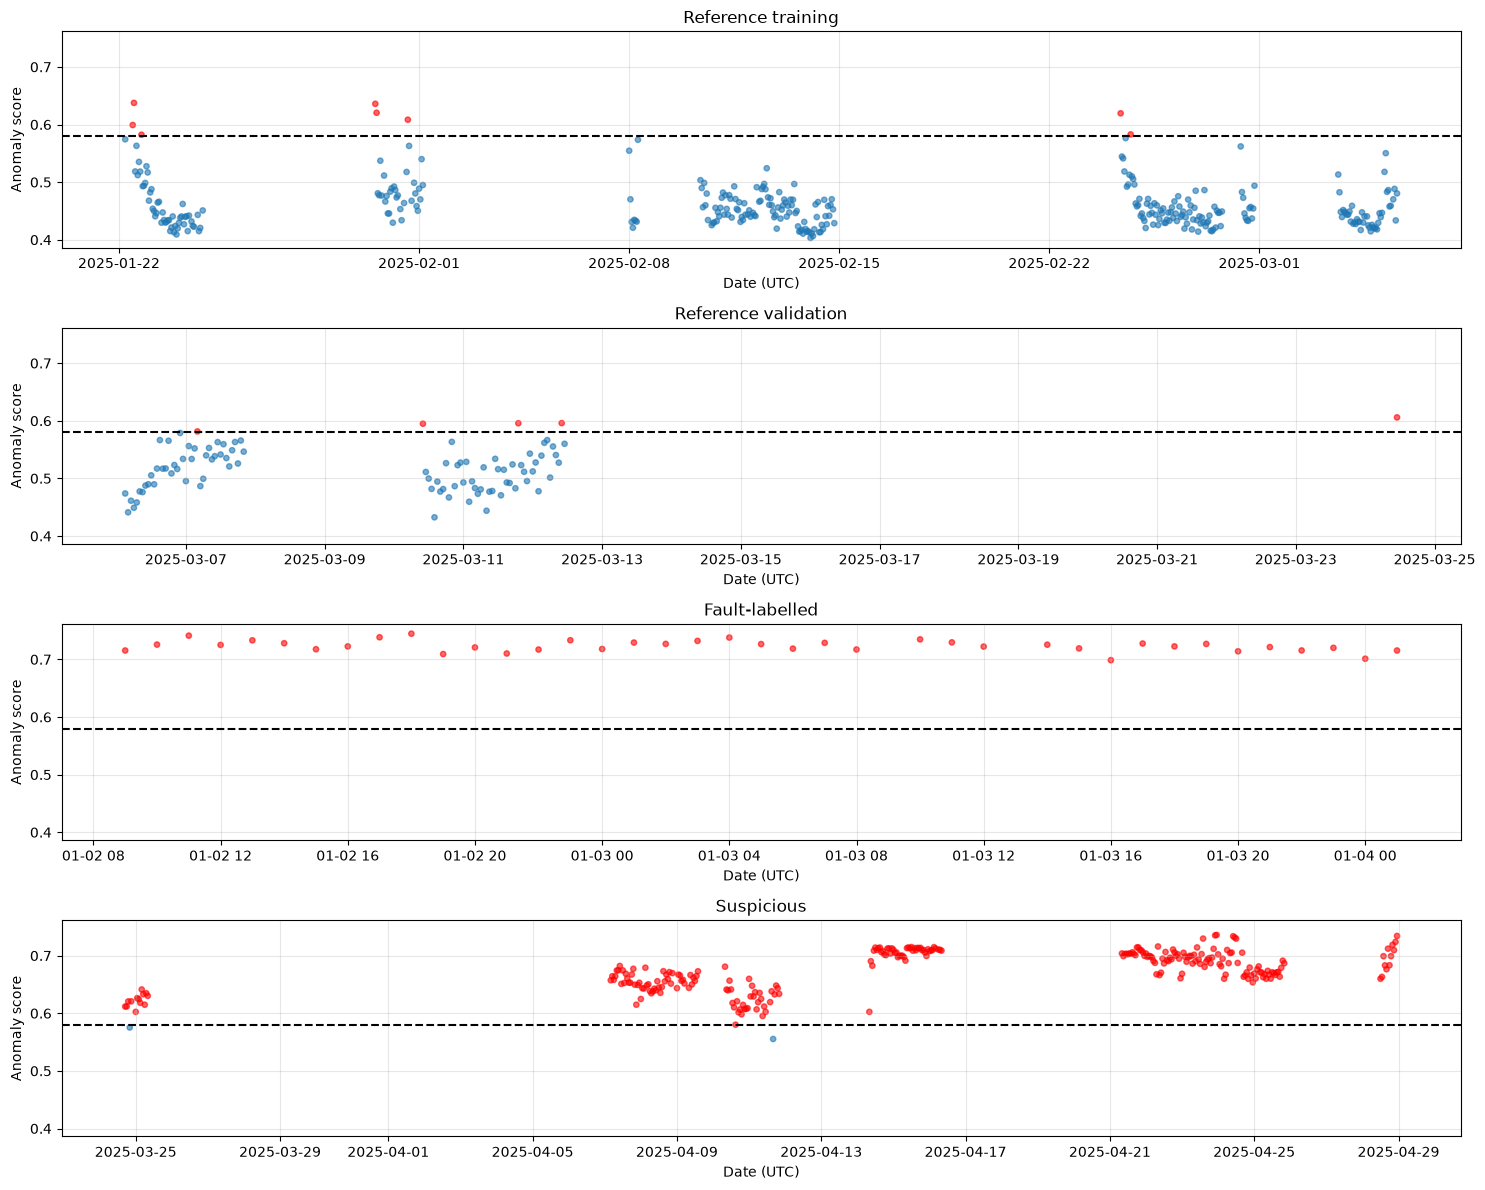


Reduced: 4 features
Reference: retained 428/428 rows
Reference recordings without a matched run: 0
Training run IDs: [2, 3, 4, 5, 6, 7, 8, 9]
Validation run IDs: [10, 11, 12]
Fault-labelled: retained 39/39 rows
Suspicious: retained 271/271 rows

Frozen score threshold: 0.6206


,recordings,flagged,flagged_pct,median_score
group,,,,
Reference training,335,5,1.493,0.438
Reference validation,93,5,5.376,0.508
Fault-labelled,39,39,100.000,0.754
Suspicious,271,268,98.893,0.744


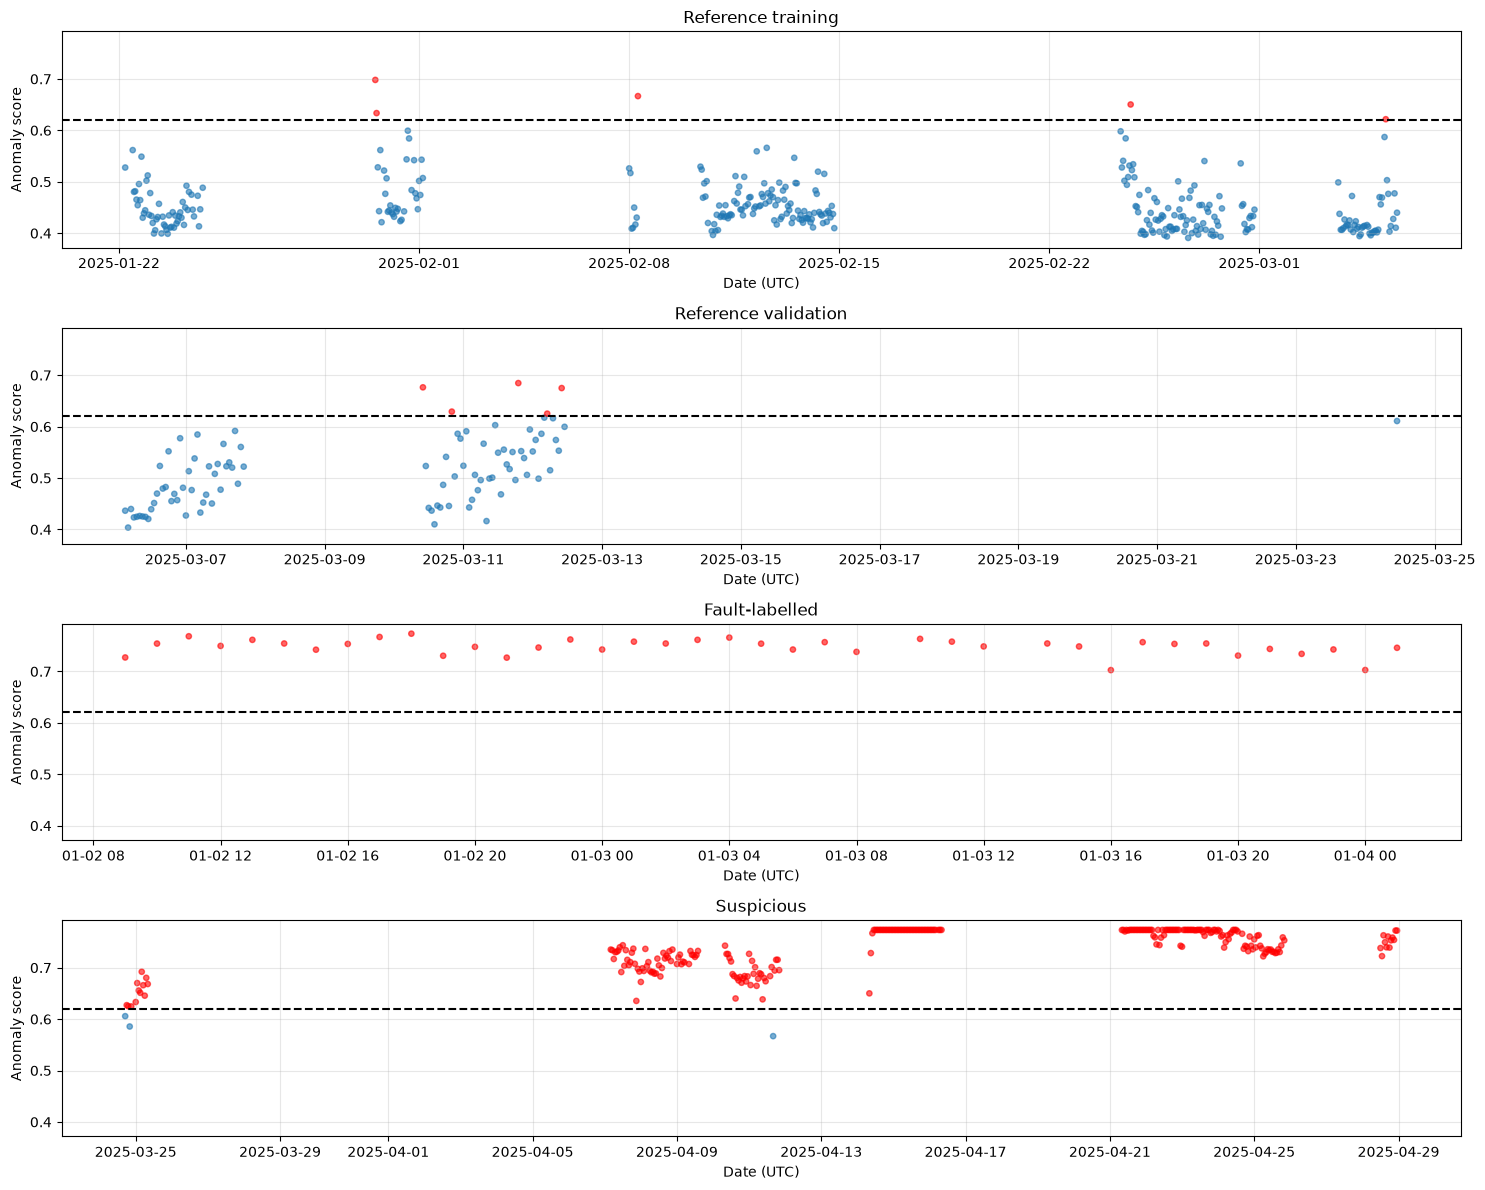


Reduced + Z LF RMS: 5 features
Reference: retained 428/428 rows
Reference recordings without a matched run: 0
Training run IDs: [2, 3, 4, 5, 6, 7, 8, 9]
Validation run IDs: [10, 11, 12]
Fault-labelled: retained 39/39 rows
Suspicious: retained 271/271 rows

Frozen score threshold: 0.5854


,recordings,flagged,flagged_pct,median_score
group,,,,
Reference training,335,9,2.687,0.433
Reference validation,93,5,5.376,0.491
Fault-labelled,39,39,100.000,0.759
Suspicious,271,267,98.524,0.757


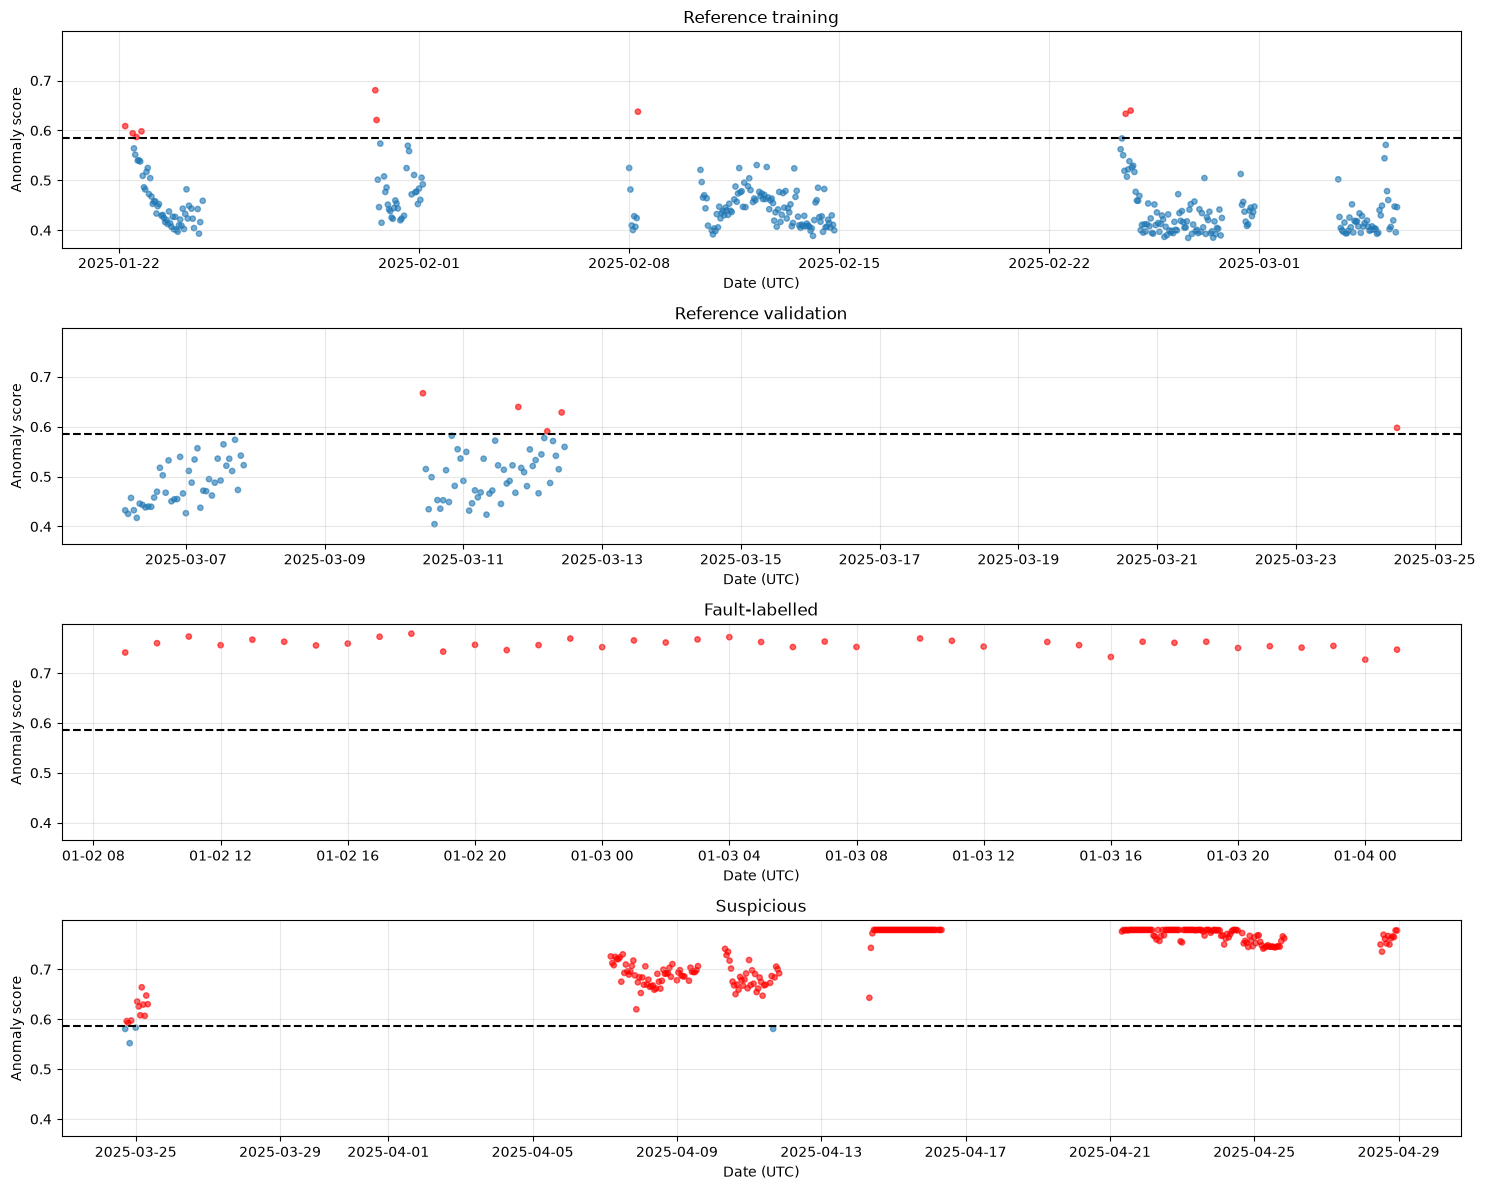

,features,healthy_validation_n,fault_n,healthy_false_alarm_rate,fault_recall,fault_precision,fault_f1,accuracy,balanced_accuracy,roc_auc,suspicious_flagged_rate,threshold
model,,,,,,,,,,,,
Baseline: 8 features,8,93,39,0.0538,1.0,0.8864,0.9398,0.9621,0.9731,1.0,0.9926,0.5799
Reduced: 4 features,4,93,39,0.0538,1.0,0.8864,0.9398,0.9621,0.9731,1.0,0.9889,0.6206
Reduced + Z LF RMS: 5 features,5,93,39,0.0538,1.0,0.8864,0.9398,0.9621,0.9731,1.0,0.9852,0.5854


In [296]:
comparison_results = {}
metric_rows = []
expected_split = None

for name, columns in FEATURE_SETS.items():
    print(f"\n{'=' * 60}\n{name}")

    fitted_model, threshold, scored = train_anomaly_baseline(
        reference_df=comparison_reference,
        other_groups={
            "Fault-labelled": comparison_fault,
            "Suspicious": comparison_suspicious,
        },
        feature_columns=columns,
        validation_fraction=0.25,
        target_false_alarm_rate=0.05,
    )

    # Verify that every experiment uses exactly the same reference split.
    split = (
        tuple(scored["Reference training"]["run_id"].unique()),
        tuple(scored["Reference validation"]["run_id"].unique()),
    )

    if expected_split is None:
        expected_split = split
    elif split != expected_split:
        raise ValueError("Models used different training/validation runs.")

    healthy = scored["Reference validation"]
    fault = scored["Fault-labelled"]
    suspicious = scored["Suspicious"]

    if healthy.empty or fault.empty:
        raise ValueError("Need healthy-validation and fault recordings.")

    evaluation = pd.concat([
        healthy.assign(actual=0),
        fault.assign(actual=1),
    ], ignore_index=True)

    y_true = evaluation["actual"]
    y_pred = evaluation["anomaly"].astype(int)

    metric_rows.append({
        "model": name,
        "features": len(columns),
        "healthy_validation_n": len(healthy),
        "fault_n": len(fault),
        "healthy_false_alarm_rate": healthy["anomaly"].mean(),
        "fault_recall": recall_score(y_true, y_pred, zero_division=0),
        "fault_precision": precision_score(y_true, y_pred, zero_division=0),
        "fault_f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "roc_auc": roc_auc_score(
            y_true, evaluation["anomaly_score"]
        ),
        "suspicious_flagged_rate": (
            suspicious["anomaly"].mean()
            if len(suspicious) else np.nan
        ),
        "threshold": threshold,
    })

    comparison_results[name] = {
        "model": fitted_model,
        "threshold": threshold,
        "scored_groups": scored,
        "feature_columns": columns,
    }

model_comparison = pd.DataFrame(metric_rows).set_index("model")
display(model_comparison.round(4))

Each feature set is fitted using the same healthy training and validation runs. Each model receives its own threshold calibrated at the same nominal 5% healthy false-alarm target. Metrics use **93 healthy validation recordings as negatives** and **39 fault-labelled recordings as positives**; suspicious recordings are reported separately because their fault status is unconfirmed.

| Metric | Eight features | Four features | Five features |
|---|---:|---:|---:|
| Healthy validation false-alarm rate | 5.38% | 5.38% | 5.38% |
| Fault-labelled recall | 100% | 100% | 100% |
| Fault-labelled precision | 88.64% | 88.64% | 88.64% |
| F1 score | 93.98% | 93.98% | 93.98% |
| Accuracy | 96.21% | 96.21% | 96.21% |
| Balanced accuracy | 97.31% | 97.31% | 97.31% |
| ROC AUC | 1.00 | 1.00 | 1.00 |
| Suspicious recordings flagged | 99.26% | 98.89% | 98.52% |

All models detect the 39 fault-labelled recordings and flag five healthy validation recordings. Recall measures the proportion of fault-labelled recordings detected; precision measures the proportion of flags that belong to the fault-labelled group in this evaluation sample. F1 balances precision and recall. Balanced accuracy averages fault recall and healthy specificity. ROC AUC measures score ranking across thresholds: **AUC = 1 does not imply zero false alarms at the selected threshold**.

The four-feature model achieves the same labelled evaluation metrics with fewer inputs, supporting its selection as the simpler candidate. The extra fifth feature does not improve these metrics. Suspicious flag rates cannot be interpreted as fault recall, and lower or higher suspicious flag rates alone do not establish a better model.

These are development results rather than independent estimates of deployment accuracy: healthy validation data calibrate the thresholds, feature reduction uses group comparisons, and the 39 fault recordings come from one episode. Precision also depends on the evaluation class balance. Independent labelled runs are needed to assess generalization.


### Save the selected model and calibrated threshold


In [297]:
from pathlib import Path
import joblib
import sklearn

selected = comparison_results["Reduced: 4 features"]
final_model = selected["model"]
final_threshold = float(selected["threshold"])
MODEL_PATH = Path("artifacts/bearing_anomaly_model.joblib")
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "format_version": 1,
    "model": final_model,
    "threshold": final_threshold,
    "feature_columns": list(final_model.feature_names_in_),
    "sklearn_version": sklearn.__version__,
    "score_method": "negative_score_samples",
    "decision_rule": "anomaly_score > threshold",
}
joblib.dump(model_bundle, MODEL_PATH, compress=3)
print(f"Saved model bundle to {MODEL_PATH.resolve()}")


Saved model bundle to /Users/vinura/Work/Personal/Interviews/Groundupai/Vinura_Wanniarachchi_AIMLEngineer_Groundup/artifacts/bearing_anomaly_model.joblib


The fitted four-feature model is saved together with its exact feature order, frozen threshold, score convention, artifact format version, and scikit-learn version. Inference loads this bundle and flags scores strictly greater than the threshold, matching notebook predictions. The artifact contains a healthy-reference anomaly detector, not a confirmed bearing-fault classifier. Load only trusted joblib artifacts.


### Score the holdout with the frozen four-feature model


Total holdout records: 10,523
Likely active waveform recordings: 344
Envelope feature available: 344/344
Scorable active recordings: 340/344
Excluded for invalid dates/features: 4
Frozen threshold: 0.620584
Flagged recordings: 340
Flagged proportion: 100.00%


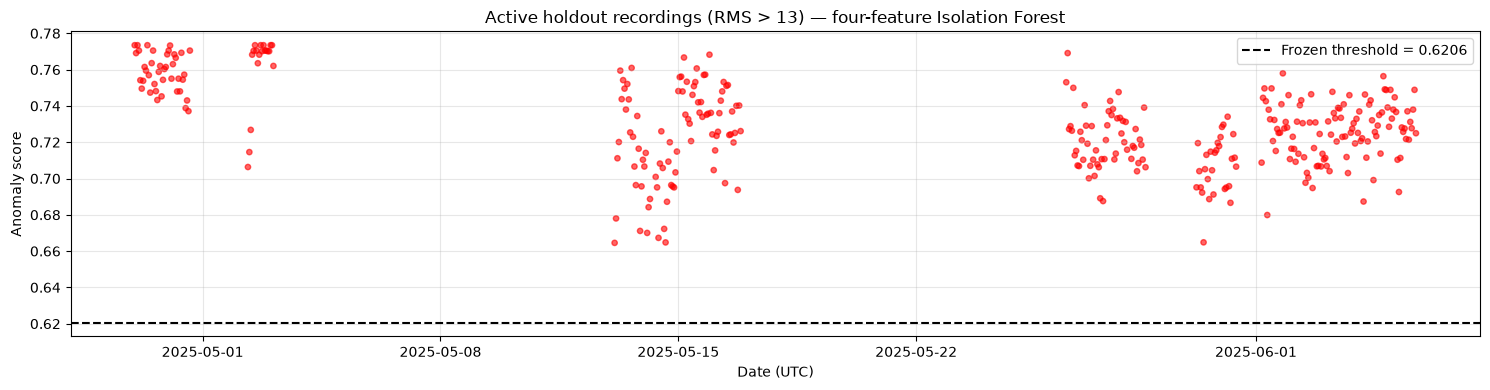

In [298]:
# 1. Select the fitted four-feature model.
selected = comparison_results["Reduced: 4 features"]

final_model = selected["model"]
final_threshold = float(selected["threshold"])
trained_columns = list(final_model.feature_names_in_)

# 2. Keep likely active holdout recordings using the training criterion.
df_hold_out_active = df_hold_out.copy()

df_hold_out_active[CALCULATED_SHF_RMS_COL] = (
    df_hold_out_active["Motor DE_Z Short Wave High Frequency"]
    .map(calculate_raw_waveform_rms)
)

rms = pd.to_numeric(
    df_hold_out_active[CALCULATED_SHF_RMS_COL],
    errors="coerce",
)

active_mask = np.isfinite(rms) & (rms > 13)

print(f"Total holdout records: {len(df_hold_out_active):,}")
print(f"Likely active waveform recordings: {active_mask.sum():,}")

df_hold_out_active = df_hold_out_active.loc[active_mask].copy()

if df_hold_out_active.empty:
    raise ValueError("No holdout waveform recordings have finite RMS > 13.")

# 3. Extract features using the same processing as training.
features_hold_out = extract_signal_features(
    df_hold_out_active,
    WAVE_FS,
)
df_hold_out_selected = build_selected_features(features_hold_out)

hold_out = add_envelope_feature(
    df_hold_out_selected,
    df_hold_out_active,
)

hold_out["date"] = pd.to_datetime(
    hold_out["date"], utc=True, errors="coerce"
)

missing = [
    column for column in trained_columns
    if column not in hold_out.columns
]
if missing:
    raise KeyError(f"Missing holdout features: {missing}")

hold_out[trained_columns] = (
    hold_out[trained_columns]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

valid = (
    hold_out["date"].notna()
    & hold_out[trained_columns].notna().all(axis=1)
)

print(f"Scorable active recordings: {valid.sum():,}/{len(hold_out):,}")
print(f"Excluded for invalid dates/features: {(~valid).sum():,}")

hold_out_scores = hold_out.loc[valid].sort_values("date").copy()

if hold_out_scores.empty:
    raise ValueError("No complete active holdout recordings available.")

# 4. Score without retraining or adjusting the threshold.
hold_out_scores["anomaly_score"] = -final_model.score_samples(
    hold_out_scores[trained_columns]
)
hold_out_scores["anomaly"] = (
    hold_out_scores["anomaly_score"] > final_threshold
)

print(f"Frozen threshold: {final_threshold:.6f}")
print(f"Flagged recordings: {hold_out_scores['anomaly'].sum():,}")
print(f"Flagged proportion: {hold_out_scores['anomaly'].mean():.2%}")

# 5. Plot predictions for likely active recordings only.
plt.figure(figsize=(15, 4))
plt.scatter(
    hold_out_scores["date"],
    hold_out_scores["anomaly_score"],
    c=np.where(hold_out_scores["anomaly"], "red", "tab:blue"),
    s=15,
    alpha=0.6,
)
plt.axhline(
    final_threshold,
    color="black",
    linestyle="--",
    label=f"Frozen threshold = {final_threshold:.4f}",
)
plt.xlabel("Date (UTC)")
plt.ylabel("Anomaly score")
plt.title("Active holdout recordings (RMS > 13) — four-feature Isolation Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The fitted four-feature model and its threshold are reused without retraining or threshold adjustment. Holdout waveforms pass through the same feature extraction, selected-band construction, and envelope processing. Recordings missing any required feature are excluded before scoring.

The saved output contains **716 candidate recordings**, of which **706 are scorable** and **10 are excluded**. At the frozen threshold of approximately **0.620584**, **706/706 scorable recordings (100%)** are flagged.

This means every scored holdout recording departs from the learned healthy reference at this threshold. It does **not** establish that every recording contains a bearing fault: holdout ground-truth labels are unavailable, so accuracy, precision, and recall cannot be calculated here.

**Comparability limitation:** development groups were filtered to calculated short-wave high-frequency RMS **> 13**, but this holdout block does not apply that running filter. It may therefore score operating states absent from training. Before interpreting the universal flag rate as deterioration, compare running-only holdout scores and examine feature distributions and operating-condition changes. The current result should be presented as an anomaly-screening outcome.


### Record the final model and feature configuration


In [299]:
FINAL_FEATURES = [
    "z_acc_2500_5000_rms",
    "z_acc_2500_5000_power_fraction",
    "z_hf_envelope_median_5_500",
    "y_vel_100_500_power_fraction",
]

selected = comparison_results["Reduced: 4 features"]

final_model = selected["model"]
final_threshold = selected["threshold"]

The notebook records the four selected feature names and references the already fitted reduced model and its frozen threshold. This block does not retrain the model, export it, or calibrate a new threshold.

The final output is a healthy-reference anomaly detector using Z acceleration band RMS, Z acceleration power fraction, Z envelope-spectrum median, and Y velocity power fraction. Its development results support further investigation, while the unlabelled holdout results and operating-state mismatch limit claims of confirmed bearing-fault detection.


### Run inference using the saved model


In [300]:
from model_inferer import ModelInferer

inferer = ModelInferer(MODEL_PATH)
# Pass the engineered features, not raw waveforms.
inference_results = inferer.predict(hold_out_scores[inferer.feature_columns])
display(inference_results.head())


,anomaly_score,threshold,anomaly
0,0.773449,0.620584,True
1,0.769100,0.620584,True
2,0.773449,0.620584,True
3,0.770489,0.620584,True
4,0.754157,0.620584,True


`ModelInferer` loads the saved model bundle and scores supplied feature dictionaries or DataFrames without retraining. It enforces the saved feature order, rejects missing or non-finite feature values, and applies the frozen threshold. The output includes the anomaly score, threshold, and boolean anomaly flag for each recording. Features must be engineered using the same processing and units as training. An anomaly flag is not a confirmed bearing-fault diagnosis.
